# Dry Bean Dataset — Complete Machine Learning Notebook
**Tasks:** EDA, multiclass classification, regression, complete ML pipeline, K-Means, DBSCAN, feature selection, PCA, Stratified K-Fold, and voting ensembles.

> Run the cells in order. The dataset is downloaded from the UCI Machine Learning Repository. The target `Class` has seven bean varieties.

## 1. Import libraries

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score
)

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, VotingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset

In [ ]:
# Download the UCI Dry Bean dataset archive and read its Excel file
import urllib.request, zipfile, io

url = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
response = urllib.request.urlopen(url)
archive = zipfile.ZipFile(io.BytesIO(response.read()))

excel_name = next(name for name in archive.namelist()
                  if name.lower().endswith(".xlsx") and "dry" in name.lower())
with archive.open(excel_name) as file:
    df = pd.read_excel(file)

df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:
print("Shape:", df.shape)
print("\\nColumns:")
print(df.columns.tolist())
print("\\nData types:")
display(df.dtypes)
print("\\nClass counts:")
display(df["Class"].value_counts())

Shape: (13611, 17)
\nColumns:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']
\nData types:


,0
Area,int64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,int64
EquivDiameter,float64
Extent,float64
Solidity,float64


\nClass counts:


,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


## 3. Data cleaning and preprocessing

In [ ]:
print("Missing values per column:")
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates().reset_index(drop=True)

# Basic summary
display(df.describe().T)

Missing values per column:


,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


Duplicate rows: 68


,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460385,29392.438324,20420.000000,36282.500000,44580.000000,61382.000000,254616.000000
Perimeter,13543.0,854.993406,214.722684,524.736000,703.230000,793.896000,977.146500,1985.370000
MajorAxisLength,13543.0,319.895602,85.809260,183.601165,253.086806,296.404589,376.312489,738.860153
MinorAxisLength,13543.0,202.365321,45.051632,122.512653,175.886357,192.491117,217.245403,460.198497
AspectRation,13543.0,1.581075,0.245245,1.024868,1.430662,1.549860,1.703916,2.430306
Eccentricity,13543.0,0.750315,0.091858,0.218951,0.715144,0.763997,0.809671,0.911423
ConvexArea,13543.0,53767.986709,29844.248525,20684.000000,36673.000000,45122.000000,62360.000000,263261.000000
EquivDiameter,13543.0,253.034094,59.307709,161.243764,214.933277,238.245711,279.560351,569.374358
Extent,13543.0,0.749829,0.048939,0.555315,0.718735,0.759903,0.786849,0.866195
Solidity,13543.0,0.987152,0.004650,0.919246,0.985678,0.988288,0.990019,0.994677


## 4. Exploratory Data Analysis (EDA)

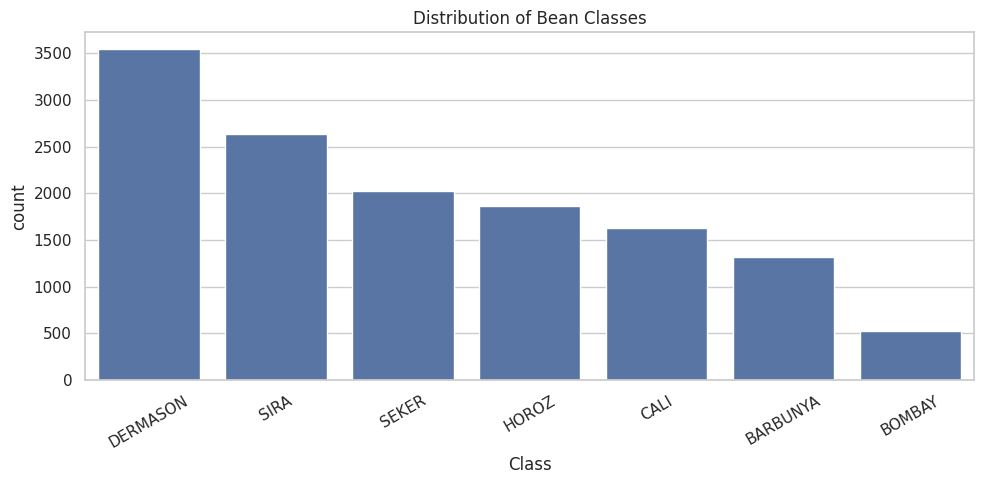

In [ ]:
# Target distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index)
plt.title("Distribution of Bean Classes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

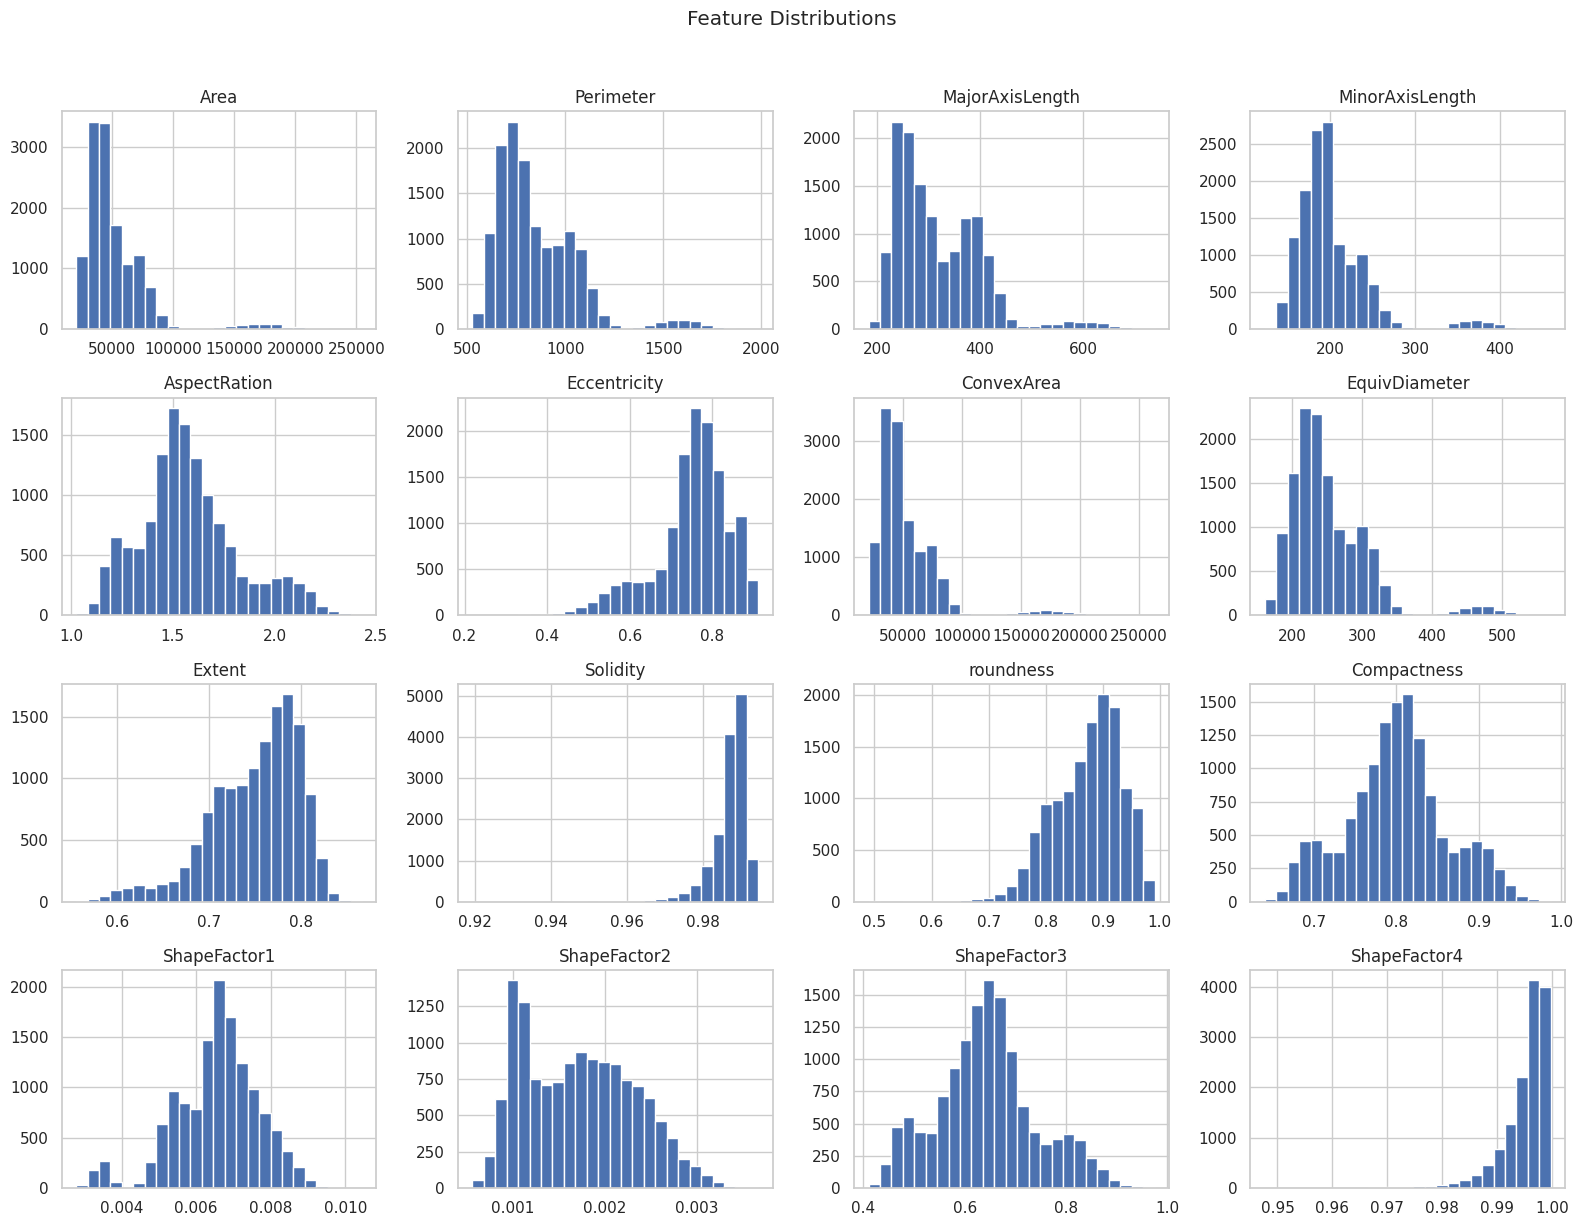

In [ ]:
# Histograms for numerical features
df.drop(columns="Class").hist(figsize=(16, 12), bins=25)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

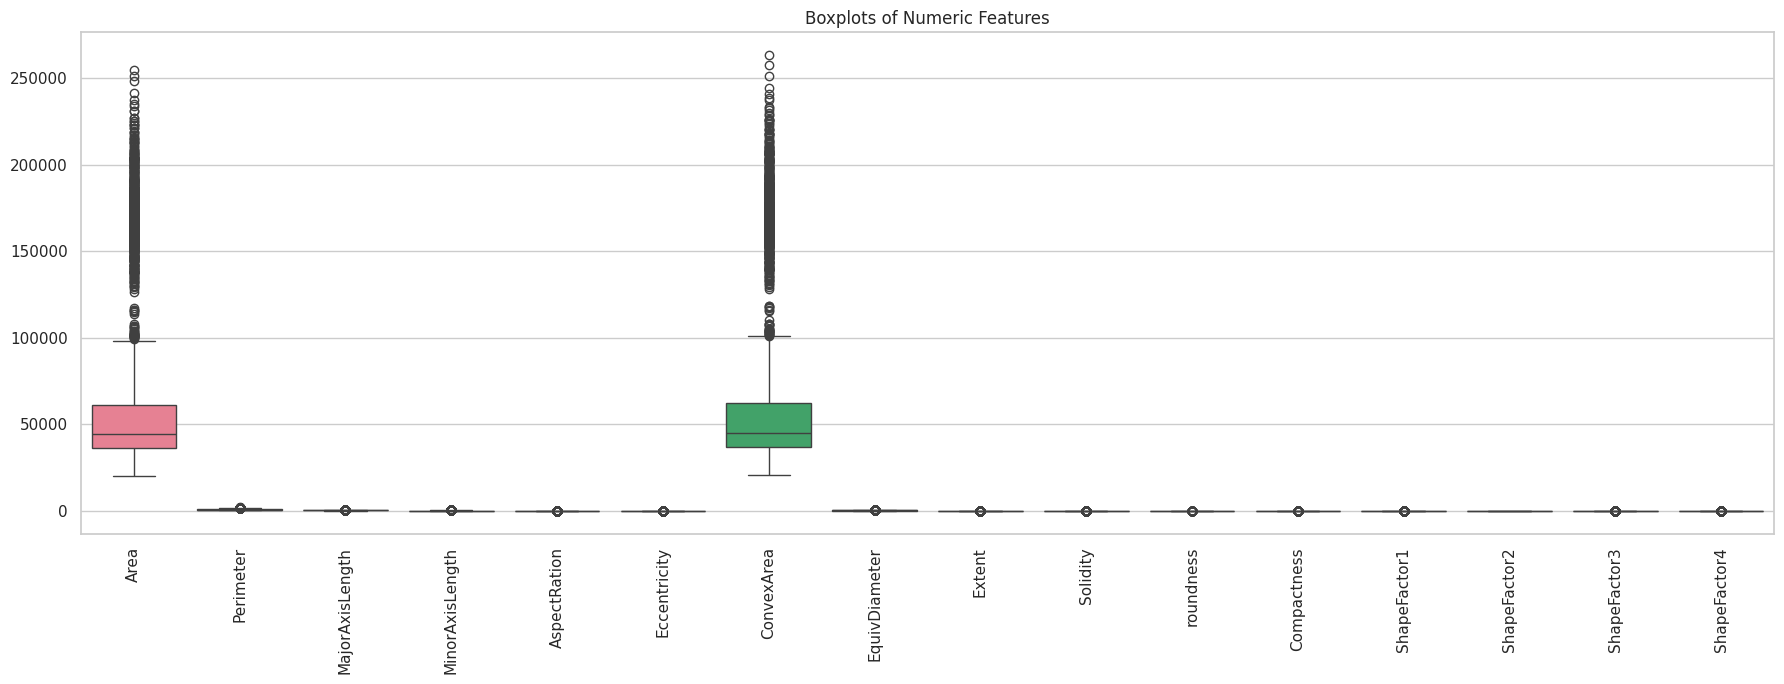

In [ ]:
# Boxplots to inspect spread and potential outliers
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(18, 7))
sns.boxplot(data=df[numeric_cols])
plt.xticks(rotation=90)
plt.title("Boxplots of Numeric Features")
plt.tight_layout()
plt.show()

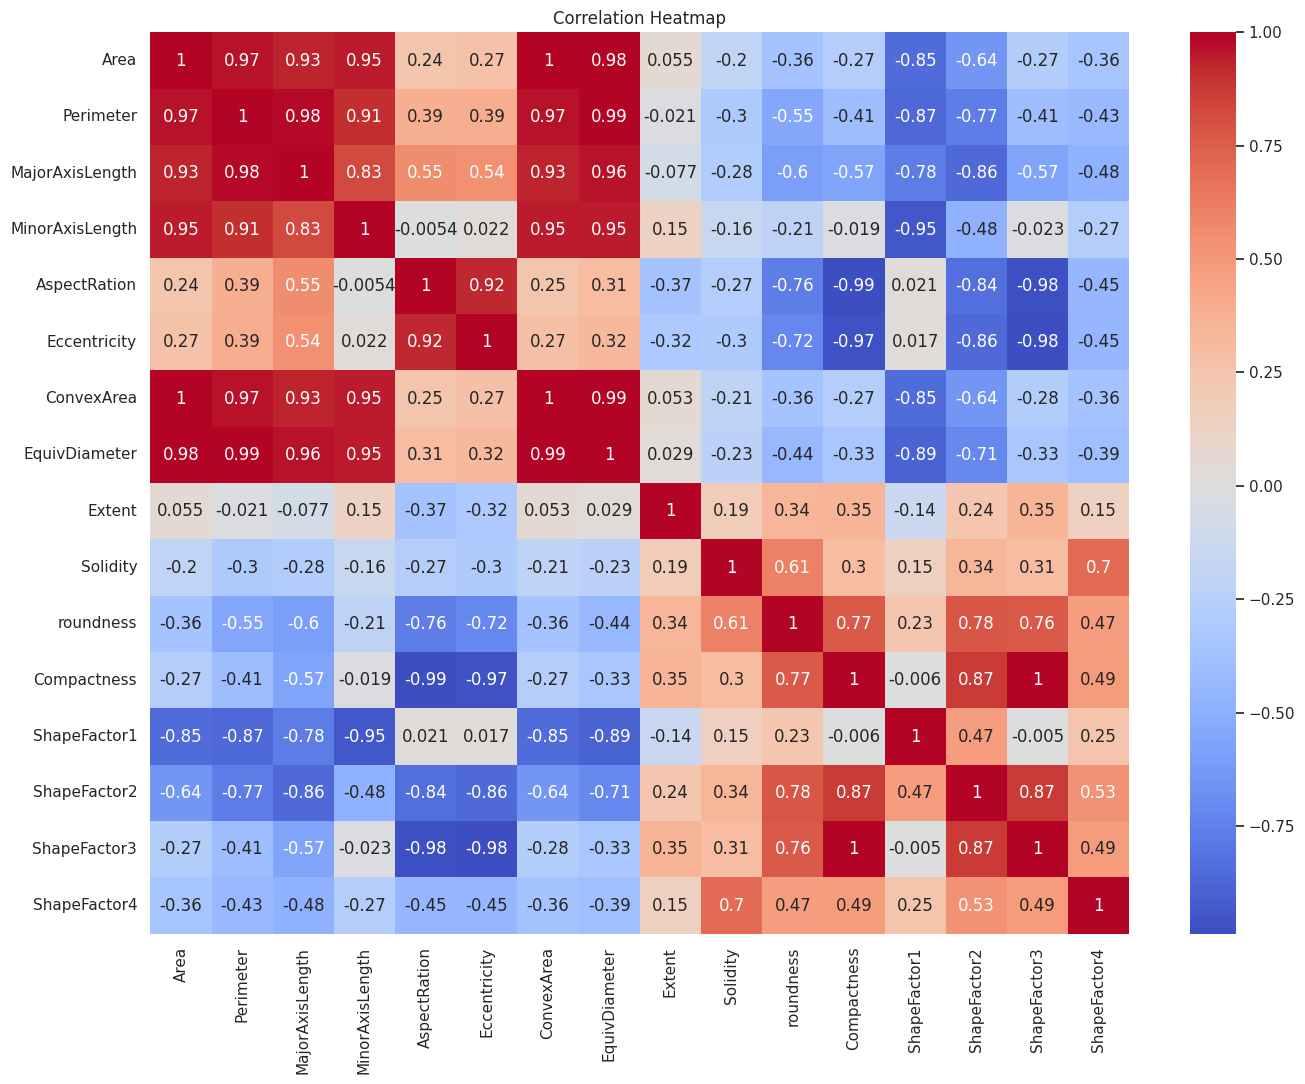

In [ ]:
# Correlation heatmap
plt.figure(figsize=(14, 11))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0, annot=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

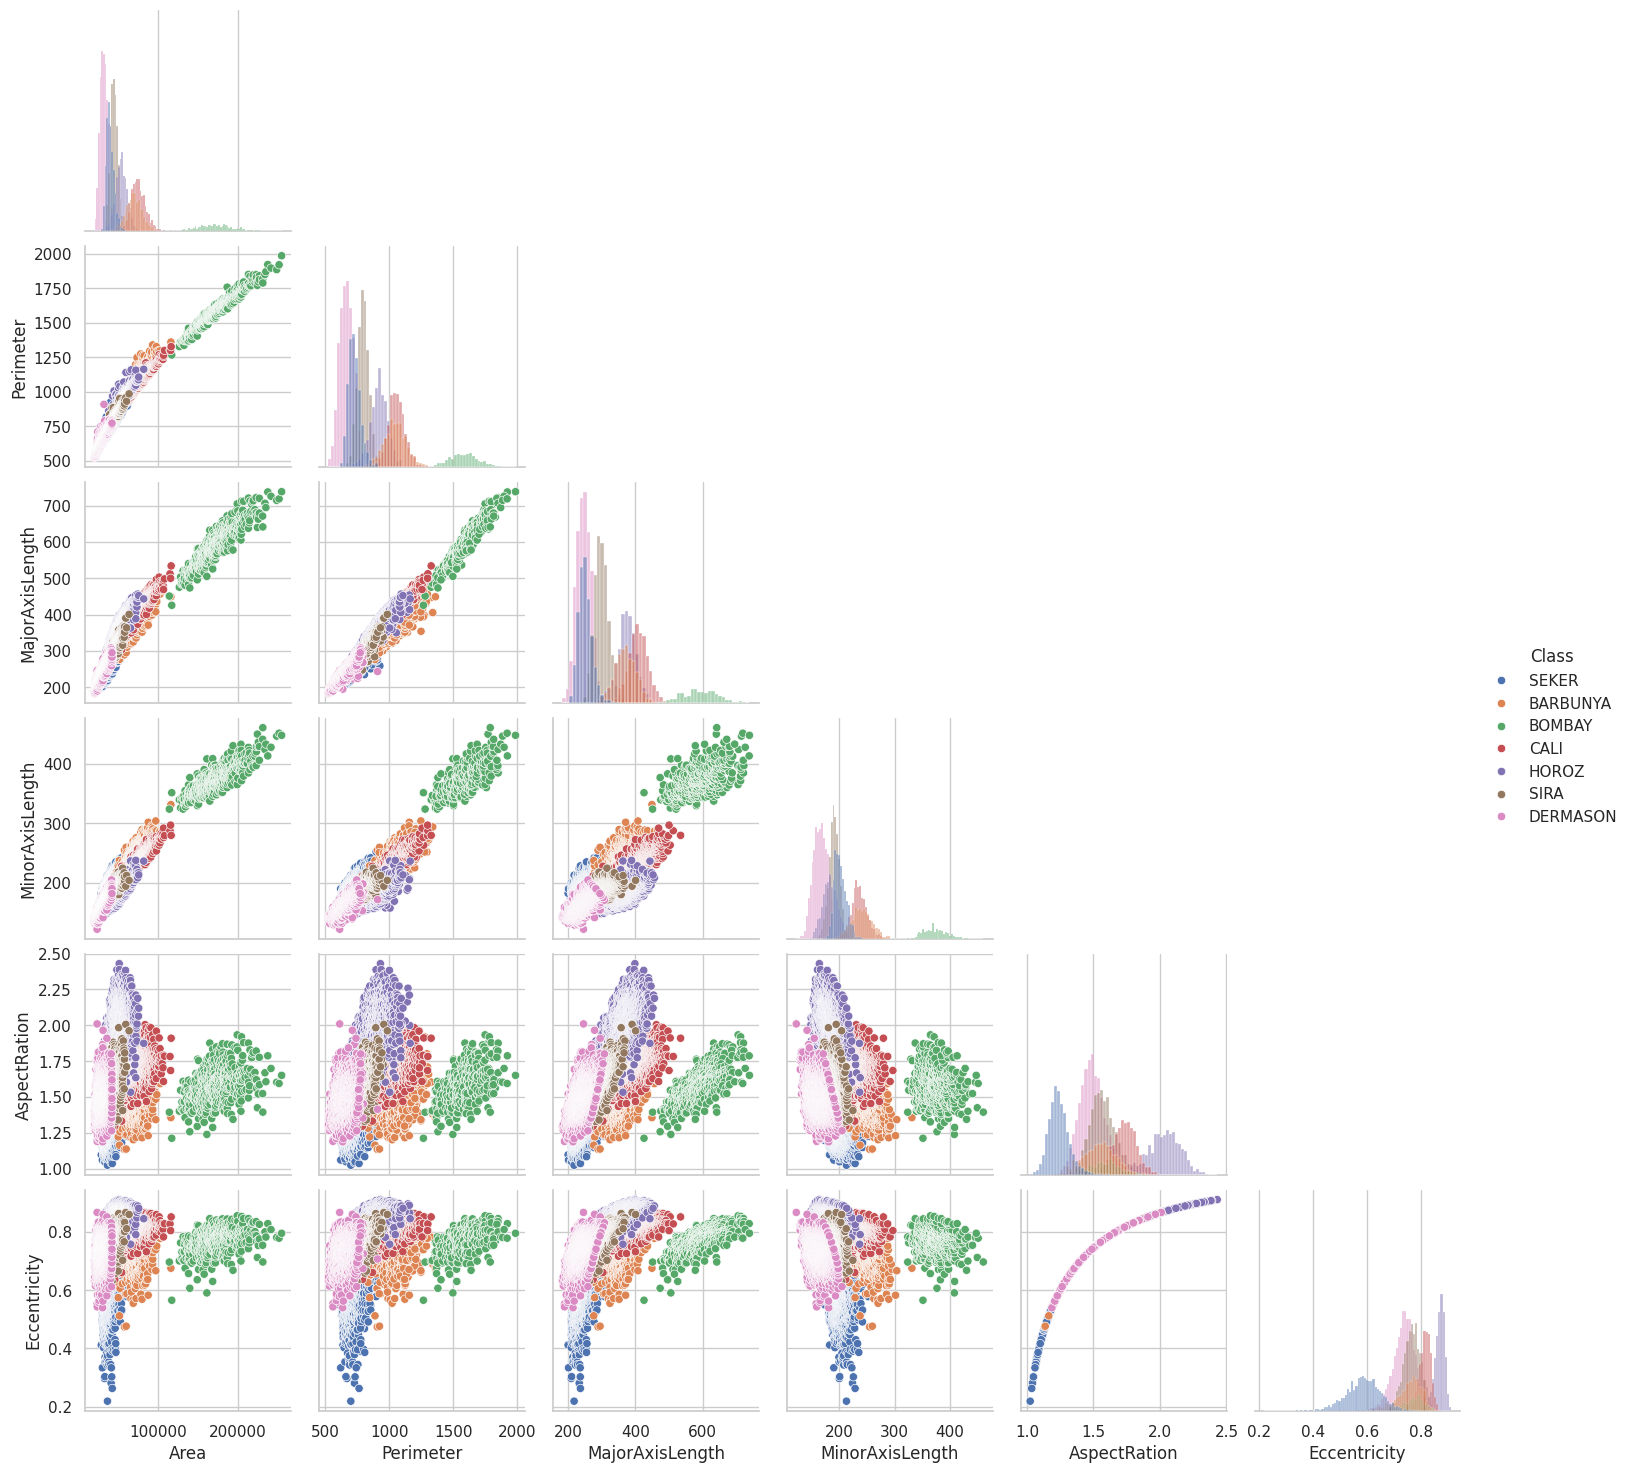

In [ ]:
# Pairwise relationships for selected features, colored by class
selected_for_pairplot = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
                         "AspectRation", "Eccentricity", "Class"]
sns.pairplot(df[selected_for_pairplot], hue="Class", corner=True, diag_kind="hist")
plt.show()

## 5. Multiclass classification

Predict the bean variety (`Class`) from the measured numerical features. We use a stratified train-test split to preserve class proportions.

In [ ]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (10834, 16)
Testing set: (2709, 16)


In [ ]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
}

classification_results = []
fitted_models = {}

for name, model in classifiers.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro"),
        "Recall (macro)": recall_score(y_test, pred, average="macro"),
        "F1 (macro)": f1_score(y_test, pred, average="macro")
    })

classification_results = pd.DataFrame(classification_results).sort_values("F1 (macro)", ascending=False)
display(classification_results)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
4,SVM (RBF),0.921004,0.934229,0.931703,0.932807
3,Random Forest,0.919897,0.932197,0.930018,0.931026
0,Logistic Regression,0.919158,0.930725,0.930049,0.930237
1,KNN,0.915467,0.928993,0.925628,0.927027
2,Decision Tree,0.896641,0.910910,0.911220,0.910923


Best model: SVM (RBF)
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



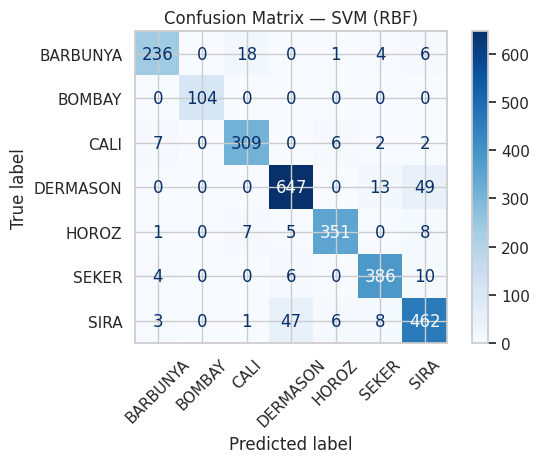

In [ ]:
best_name = classification_results.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test)

print("Best model:", best_name)
print(classification_report(y_test, best_pred))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, xticks_rotation=45, cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 6. Regression

For a meaningful regression task, predict **Area** (bean area in pixels) using the other measurements. We exclude `Area` from predictors to avoid target leakage, and also exclude the categorical class label.

This regression task is separate from the bean-variety classification task.

In [ ]:
regression_target = "Area"
X_reg = df.drop(columns=["Area", "Class"])
y_reg = df["Area"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=RANDOM_STATE
)

regressors = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)
}

reg_results = []
reg_models = {}

for name, estimator in regressors.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])
    pipe.fit(Xr_train, yr_train)
    pred = pipe.predict(Xr_test)
    reg_models[name] = pipe
    reg_results.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred)
    })

reg_results = pd.DataFrame(reg_results).sort_values("RMSE")
display(reg_results)

,Model,MAE,RMSE,R2
3,Random Forest Regressor,14.865976,79.014512,0.999993
0,Linear Regression,53.093901,107.790636,0.999987
1,Ridge Regression,69.098815,138.330876,0.999979
2,KNN Regressor,1040.212625,1719.046329,0.996697


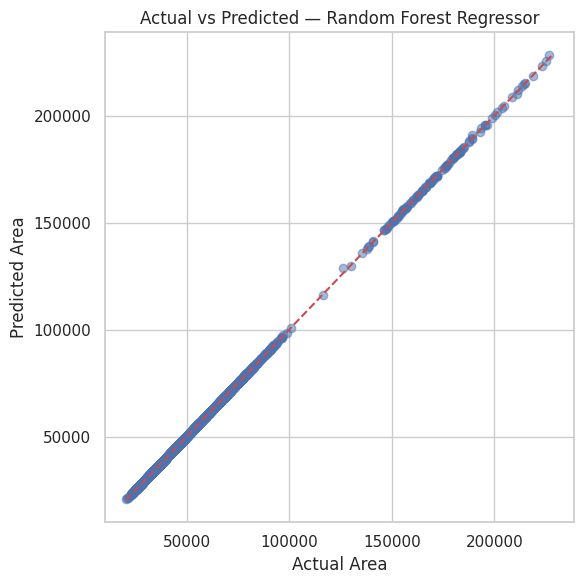

In [ ]:
reg_best_name = reg_results.iloc[0]["Model"]
reg_best = reg_models[reg_best_name]
reg_pred = reg_best.predict(Xr_test)

plt.figure(figsize=(6, 6))
plt.scatter(yr_test, reg_pred, alpha=0.5)
lims = [min(yr_test.min(), reg_pred.min()), max(yr_test.max(), reg_pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual Area")
plt.ylabel("Predicted Area")
plt.title(f"Actual vs Predicted — {reg_best_name}")
plt.tight_layout()
plt.show()

## 7. Complete Machine Learning Pipeline

A pipeline bundles imputation, scaling, and model training. This prevents preprocessing from leaking test-set information and makes the workflow reproducible.

In [ ]:
complete_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))
])

complete_pipeline.fit(X_train, y_train)
pipeline_pred = complete_pipeline.predict(X_test)
print("Pipeline accuracy:", accuracy_score(y_test, pipeline_pred))
print("Pipeline macro-F1:", f1_score(y_test, pipeline_pred, average="macro"))

Pipeline accuracy: 0.9198966408268734
Pipeline macro-F1: 0.9310257763805987


## 8. Unsupervised Learning — K-Means

K-Means requires scaled features. We compare inertia (elbow method) and silhouette score to help choose K. Since the known dataset has 7 labels, we also inspect K=7, but the unsupervised choice is not required to equal the number of classes.

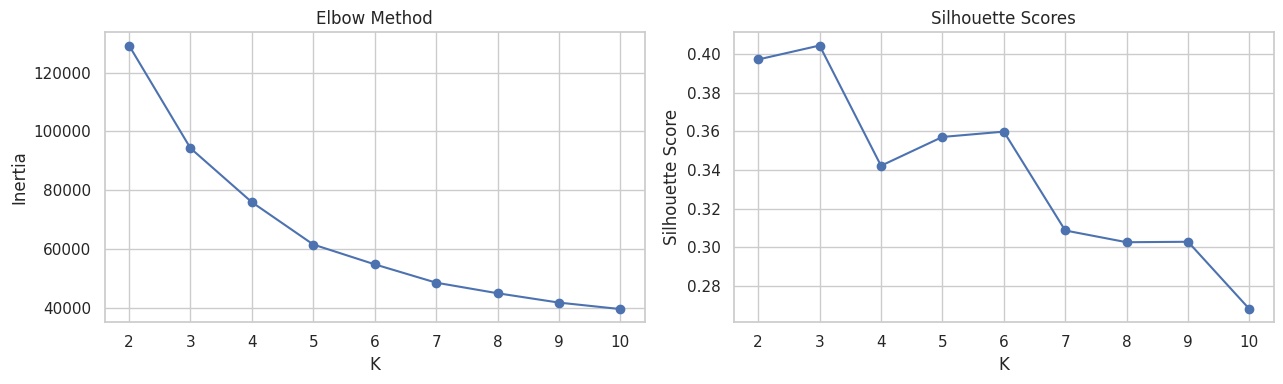

Best K by silhouette: 3


In [ ]:
X_scaled = StandardScaler().fit_transform(X)

k_values = range(2, 11)
inertias, silhouettes = [], []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow Method")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette Score"); axes[1].set_title("Silhouette Scores")
plt.tight_layout(); plt.show()

best_k_silhouette = list(k_values)[int(np.argmax(silhouettes))]
print("Best K by silhouette:", best_k_silhouette)

In [ ]:
kmeans = KMeans(n_clusters=best_k_silhouette, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster sizes:")
display(pd.Series(kmeans_labels).value_counts().sort_index())

# Compare clusters with the known labels (external descriptive comparison)
cluster_class_table = pd.crosstab(pd.Series(kmeans_labels, name="Cluster"), y)
display(cluster_class_table)

Cluster sizes:


,count
0,7567
1,524
2,5452


Class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
Cluster,,,,,,,
0,107,0,7,3506,17,2019,1911
1,1,522,1,0,0,0,0
2,1214,0,1622,40,1843,8,725


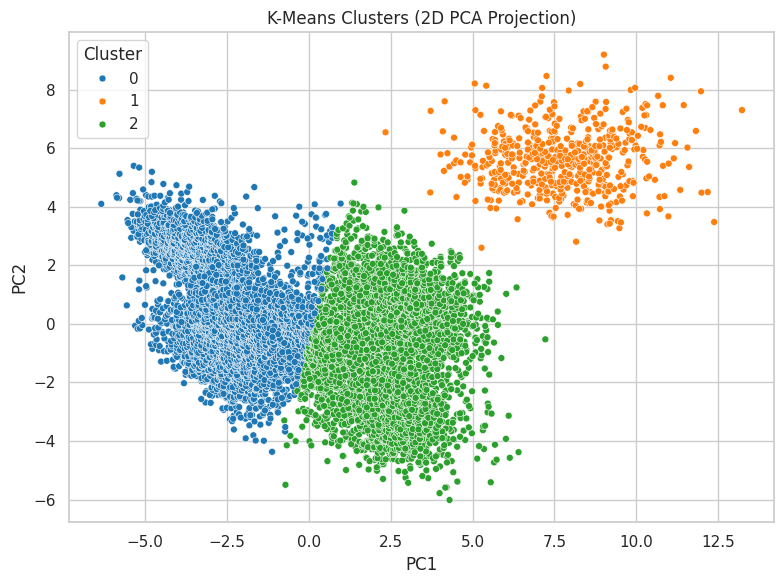

In [ ]:
# Visualize K-Means clusters with 2D PCA projection
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=kmeans_labels, palette="tab10", s=25)
plt.title("K-Means Clusters (2D PCA Projection)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout(); plt.show()

## 9. DBSCAN

DBSCAN groups dense regions and can mark points as noise (`-1`). Its results are sensitive to `eps` and `min_samples`; we test a small grid and report the number of clusters, noise fraction, and silhouette score when valid.

In [ ]:
dbscan_rows = []
dbscan_labels_by_setting = {}

for eps in [0.5, 0.8, 1.0, 1.2, 1.5, 2.0]:
    for min_samples in [5, 10]:
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_fraction = np.mean(labels == -1)
        non_noise = labels != -1
        sil = np.nan
        if n_clusters >= 2 and non_noise.sum() > n_clusters:
            try:
                sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
            except ValueError:
                pass
        dbscan_rows.append({
            "eps": eps, "min_samples": min_samples,
            "clusters (excluding noise)": n_clusters,
            "noise fraction": noise_fraction,
            "silhouette (non-noise)": sil
        })
        dbscan_labels_by_setting[(eps, min_samples)] = labels

dbscan_results = pd.DataFrame(dbscan_rows).sort_values("silhouette (non-noise)", ascending=False)
display(dbscan_results)

,eps,min_samples,clusters (excluding noise),noise fraction,silhouette (non-noise)
5,1.0,10,2,0.073027,0.573338
7,1.2,10,2,0.040095,0.571334
9,1.5,10,2,0.017057,0.570232
6,1.2,5,5,0.027837,0.413054
3,0.8,10,6,0.167836,0.335626
8,1.5,5,3,0.012036,0.274941
2,0.8,5,7,0.114819,0.046489
1,0.5,10,7,0.550247,0.042489
4,1.0,5,8,0.051909,-0.074174
0,0.5,5,60,0.438234,-0.285821


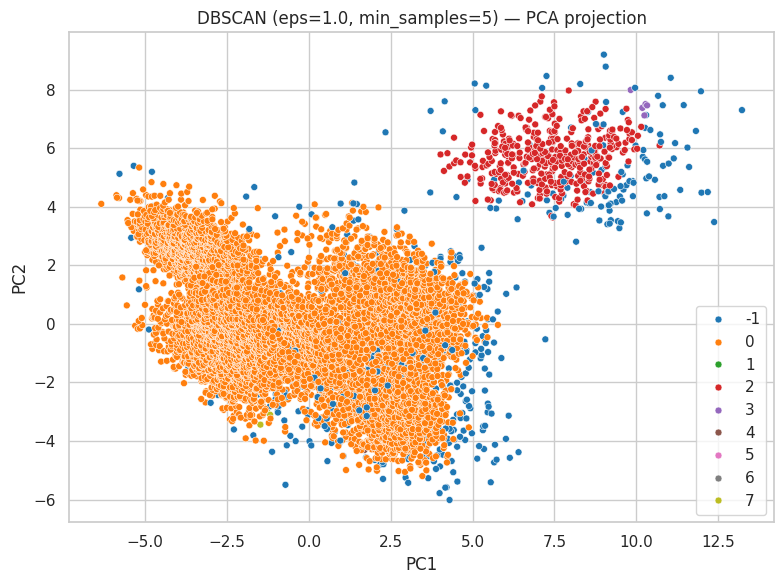

Clusters excluding noise: 8
Noise points: 703 / 13543


In [ ]:
# Visualize one DBSCAN setting (change the setting if desired)
chosen_eps, chosen_min_samples = 1.0, 5
db_labels = dbscan_labels_by_setting[(chosen_eps, chosen_min_samples)]

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=db_labels, palette="tab10", s=25)
plt.title(f"DBSCAN (eps={chosen_eps}, min_samples={chosen_min_samples}) — PCA projection")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

print("Clusters excluding noise:", len(set(db_labels)) - (1 if -1 in db_labels else 0))
print("Noise points:", np.sum(db_labels == -1), "/", len(db_labels))

## 10. Models using all features

The models in the classification section already use every predictor feature. This section provides a direct baseline table and keeps the best all-feature model as a reference for feature-selection and PCA experiments.

In [ ]:
all_feature_baseline = classification_results.copy()
display(all_feature_baseline)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
4,SVM (RBF),0.921004,0.934229,0.931703,0.932807
3,Random Forest,0.919897,0.932197,0.930018,0.931026
0,Logistic Regression,0.919158,0.930725,0.930049,0.930237
1,KNN,0.915467,0.928993,0.925628,0.927027
2,Decision Tree,0.896641,0.910910,0.911220,0.910923


## 11. Feature Selection (Scikit-learn)

We demonstrate SelectKBest with mutual information and ANOVA F-score, plus RFE with Logistic Regression. Feature selection is fitted on the training split only.

In [ ]:
# Mutual Information SelectKBest
mi_selector = SelectKBest(score_func=mutual_info_classif, k=8)
mi_selector.fit(X_train, y_train)
mi_features = X.columns[mi_selector.get_support()]
print("Selected by Mutual Information:")
print(list(mi_features))
display(pd.DataFrame({"Feature": X.columns, "MI Score": mi_selector.scores_}).sort_values("MI Score", ascending=False))

Selected by Mutual Information:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter', 'ShapeFactor1', 'ShapeFactor2']


,Feature,MI Score
1,Perimeter,1.055983
6,ConvexArea,1.035262
7,EquivDiameter,1.031605
0,Area,1.031261
2,MajorAxisLength,0.993382
13,ShapeFactor2,0.944434
12,ShapeFactor1,0.923217
3,MinorAxisLength,0.920639
11,Compactness,0.826478
14,ShapeFactor3,0.826478


In [ ]:
# ANOVA F-score SelectKBest
anova_selector = SelectKBest(score_func=f_classif, k=8)
anova_selector.fit(X_train, y_train)
anova_features = X.columns[anova_selector.get_support()]
print("Selected by ANOVA F-score:")
print(list(anova_features))
display(pd.DataFrame({"Feature": X.columns, "F Score": anova_selector.scores_}).sort_values("F Score", ascending=False))

Selected by ANOVA F-score:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter', 'ShapeFactor1', 'ShapeFactor2']


,Feature,F Score
0,Area,23439.693406
6,ConvexArea,23429.385502
7,EquivDiameter,20382.326049
1,Perimeter,19578.466541
3,MinorAxisLength,17994.602831
2,MajorAxisLength,17257.561841
13,ShapeFactor2,9734.444557
12,ShapeFactor1,9707.093481
4,AspectRation,8149.419120
11,Compactness,7997.146798


In [ ]:
# RFE: recursively remove least useful features using Logistic Regression
rfe = RFE(estimator=LogisticRegression(max_iter=3000), n_features_to_select=8)
rfe.fit(StandardScaler().fit_transform(X_train), y_train)
rfe_features = X.columns[rfe.get_support()]
print("Selected by RFE:")
print(list(rfe_features))
display(pd.DataFrame({"Feature": X.columns, "Selected": rfe.support_, "Ranking": rfe.ranking_}).sort_values("Ranking"))

Selected by RFE:
['Area', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'ConvexArea', 'EquivDiameter', 'ShapeFactor1', 'ShapeFactor2']


,Feature,Selected,Ranking
0,Area,True,1
2,MajorAxisLength,True,1
3,MinorAxisLength,True,1
4,AspectRation,True,1
7,EquivDiameter,True,1
6,ConvexArea,True,1
12,ShapeFactor1,True,1
13,ShapeFactor2,True,1
10,roundness,False,2
5,Eccentricity,False,3


In [ ]:
# Evaluate models using selected features (Mutual Information)
X_train_mi, X_test_mi = X_train[mi_features], X_test[mi_features]
selected_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))
])
selected_pipe.fit(X_train_mi, y_train)
mi_pred = selected_pipe.predict(X_test_mi)

print("All features — Random Forest:")
print("Accuracy:", accuracy_score(y_test, fitted_models["Random Forest"].predict(X_test)))
print("Macro-F1:", f1_score(y_test, fitted_models["Random Forest"].predict(X_test), average="macro"))
print("\\nMutual Information selected features — Random Forest:")
print("Accuracy:", accuracy_score(y_test, mi_pred))
print("Macro-F1:", f1_score(y_test, mi_pred, average="macro"))

All features — Random Forest:
Accuracy: 0.9198966408268734
Macro-F1: 0.9310257763805987
\nMutual Information selected features — Random Forest:
Accuracy: 0.9003322259136213
Macro-F1: 0.9129446641508843


## 12. PCA — Principal Component Analysis

PCA is performed after scaling. We inspect the explained variance of each component and cumulative explained variance to determine how many components preserve a chosen amount of information.

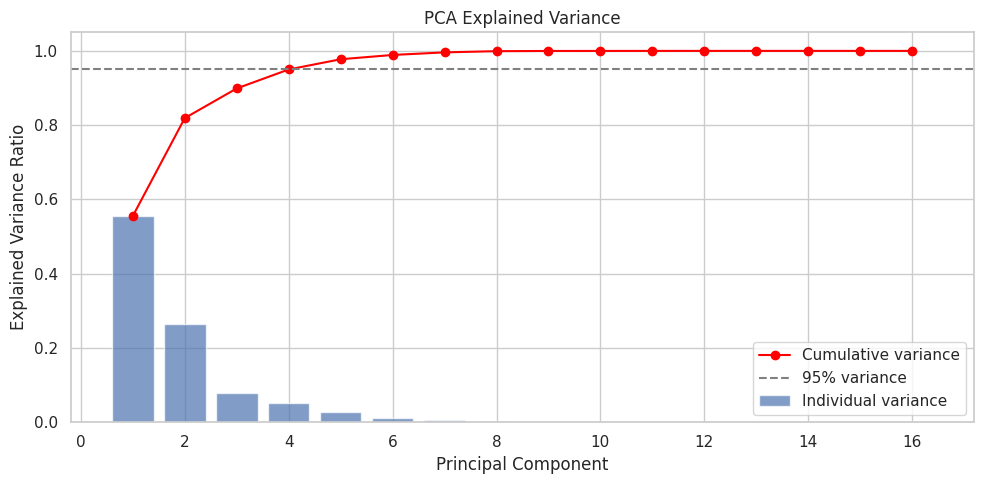

Components required for >=95% variance: 4


In [ ]:
pca_full = PCA()
X_pca = pca_full.fit_transform(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained)+1), explained, alpha=0.7, label="Individual variance")
plt.plot(range(1, len(cumulative)+1), cumulative, marker="o", color="red", label="Cumulative variance")
plt.axhline(0.95, color="gray", linestyle="--", label="95% variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

n_components_95 = np.argmax(cumulative >= 0.95) + 1
print("Components required for >=95% variance:", n_components_95)

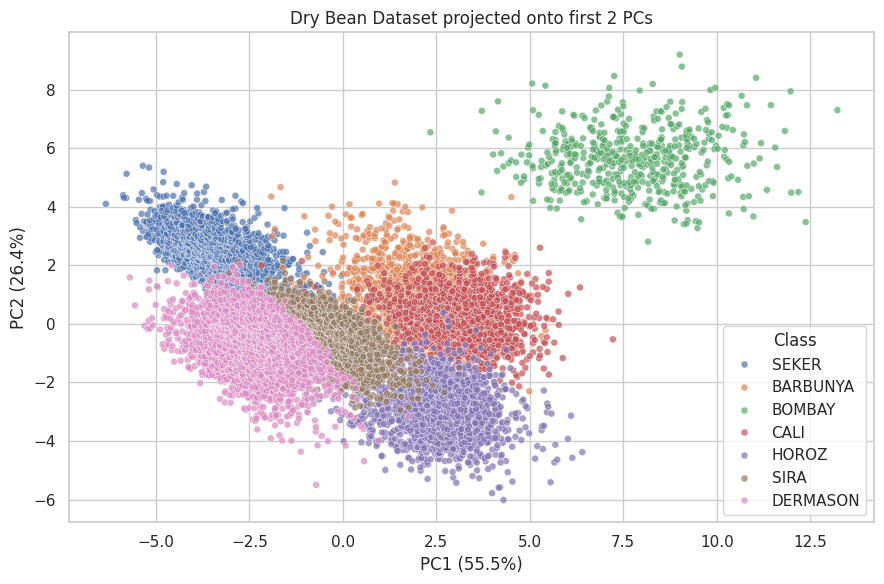

In [ ]:
# 2D PCA visualization colored by true class
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=y, s=25, alpha=0.7)
plt.title("Dry Bean Dataset projected onto first 2 PCs")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

## 13. Model development using PCA

PCA is included inside the pipeline, so it is learned only from the training data. We compare PCA retaining 95% variance with a classifier.

In [ ]:
pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95)),
    ("classifier", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))
])
pca_pipeline.fit(X_train, y_train)
pca_pred = pca_pipeline.predict(X_test)

print("PCA components used:", pca_pipeline.named_steps["pca"].n_components_)
print("PCA model accuracy:", accuracy_score(y_test, pca_pred))
print("PCA model macro-F1:", f1_score(y_test, pca_pred, average="macro"))

PCA components used: 4
PCA model accuracy: 0.8903654485049833
PCA model macro-F1: 0.8945402831521783


In [ ]:
# Compare all-feature vs PCA vs selected-feature models
comparison = pd.DataFrame([
    {"Approach": "All features - Random Forest",
     "Accuracy": accuracy_score(y_test, fitted_models["Random Forest"].predict(X_test)),
     "Macro-F1": f1_score(y_test, fitted_models["Random Forest"].predict(X_test), average="macro")},
    {"Approach": "MI-selected features - Random Forest",
     "Accuracy": accuracy_score(y_test, mi_pred),
     "Macro-F1": f1_score(y_test, mi_pred, average="macro")},
    {"Approach": "PCA (95%) - Random Forest",
     "Accuracy": accuracy_score(y_test, pca_pred),
     "Macro-F1": f1_score(y_test, pca_pred, average="macro")}
])
display(comparison.sort_values("Macro-F1", ascending=False))

,Approach,Accuracy,Macro-F1
0,All features - Random Forest,0.919897,0.931026
1,MI-selected features - Random Forest,0.900332,0.912945
2,PCA (95%) - Random Forest,0.890365,0.894540


## 14. Stratified K-Fold Cross Validation

Stratified K-Fold maintains approximately the same class distribution in every fold. We use 5 folds and report mean and standard deviation of accuracy, macro precision, macro recall, and macro-F1.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=250, random_state=RANDOM_STATE))
])

cv_scores = cross_validate(
    cv_pipeline, X, y, cv=skf,
    scoring={"accuracy": "accuracy", "precision_macro": "precision_macro",
             "recall_macro": "recall_macro", "f1_macro": "f1_macro"},
    return_train_score=False
)

cv_summary = pd.DataFrame({
    metric: [cv_scores[f"test_{metric}"].mean(), cv_scores[f"test_{metric}"].std()]
    for metric in ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
}, index=["Mean", "Std"])
display(cv_summary)

,accuracy,precision_macro,recall_macro,f1_macro
Mean,0.923725,0.936769,0.933464,0.934974
Std,0.005082,0.002963,0.003875,0.003396


## 15. Ensemble Learning

We use Logistic Regression, KNN, and Random Forest as diverse base learners. Hard voting selects the class with the most votes. Soft voting averages predicted class probabilities.

In [ ]:
voting_estimators = [
    ("lr", Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("model", LogisticRegression(max_iter=3000))])),
    ("knn", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler()),
                      ("model", KNeighborsClassifier(n_neighbors=7))])),
    ("rf", Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]))
]

### 15A. Hard Voting (Majority Voting)

In [ ]:
hard_voting = VotingClassifier(estimators=voting_estimators, voting="hard")
hard_voting.fit(X_train, y_train)
hard_pred = hard_voting.predict(X_test)

print("Hard Voting Accuracy:", accuracy_score(y_test, hard_pred))
print("Hard Voting Macro-F1:", f1_score(y_test, hard_pred, average="macro"))
print(classification_report(y_test, hard_pred))

Hard Voting Accuracy: 0.9191583610188261
Hard Voting Macro-F1: 0.9299220144136079
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.92       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.94      0.95      0.94       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



### 15B. Soft Voting (Probability Voting)

In [ ]:
soft_voting = VotingClassifier(estimators=voting_estimators, voting="soft")
soft_voting.fit(X_train, y_train)
soft_pred = soft_voting.predict(X_test)

print("Soft Voting Accuracy:", accuracy_score(y_test, soft_pred))
print("Soft Voting Macro-F1:", f1_score(y_test, soft_pred, average="macro"))
print(classification_report(y_test, soft_pred))

Soft Voting Accuracy: 0.9206349206349206
Soft Voting Macro-F1: 0.93150686316723
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.92       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.97      0.94      0.95       372
       SEKER       0.94      0.95      0.94       406
        SIRA       0.87      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



## 16. Final Model Comparison

,Model,Accuracy,Macro-F1
1,Soft Voting,0.920635,0.931507
2,All-features Random Forest,0.919897,0.931026
0,Hard Voting,0.919158,0.929922
3,Feature-selected RF,0.900332,0.912945
4,PCA Random Forest,0.890365,0.894540


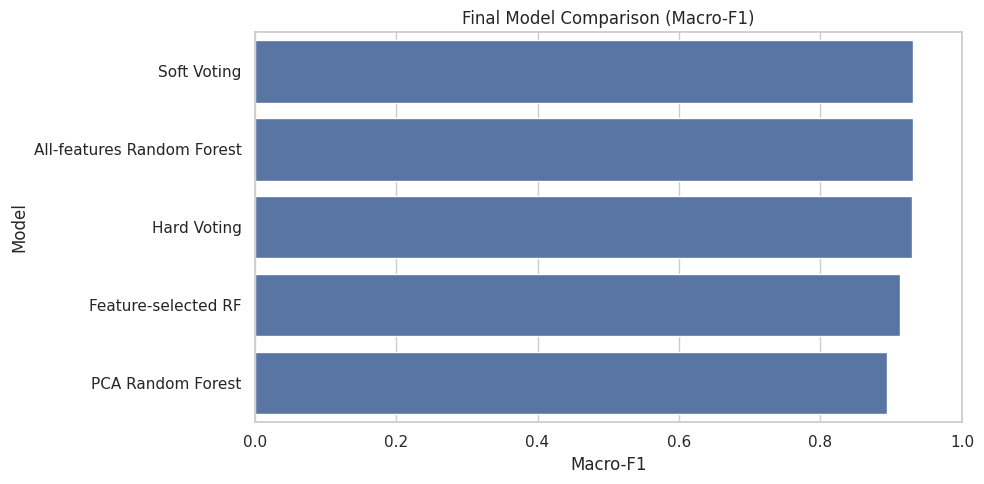

In [ ]:
final_results = [
    {"Model": "Hard Voting", "Accuracy": accuracy_score(y_test, hard_pred),
     "Macro-F1": f1_score(y_test, hard_pred, average="macro")},
    {"Model": "Soft Voting", "Accuracy": accuracy_score(y_test, soft_pred),
     "Macro-F1": f1_score(y_test, soft_pred, average="macro")},
    {"Model": "All-features Random Forest",
     "Accuracy": accuracy_score(y_test, fitted_models["Random Forest"].predict(X_test)),
     "Macro-F1": f1_score(y_test, fitted_models["Random Forest"].predict(X_test), average="macro")},
    {"Model": "Feature-selected RF", "Accuracy": accuracy_score(y_test, mi_pred),
     "Macro-F1": f1_score(y_test, mi_pred, average="macro")},
    {"Model": "PCA Random Forest", "Accuracy": accuracy_score(y_test, pca_pred),
     "Macro-F1": f1_score(y_test, pca_pred, average="macro")}
]
final_comparison = pd.DataFrame(final_results).sort_values("Macro-F1", ascending=False)
display(final_comparison)

plt.figure(figsize=(10, 5))
sns.barplot(data=final_comparison, x="Macro-F1", y="Model")
plt.title("Final Model Comparison (Macro-F1)")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()